In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 1. Load MNIST
train_data = datasets.MNIST(
    "./data", train=True, download=True,
    transform=transforms.ToTensor()
)
train_loader = DataLoader(
    train_data, batch_size=128, shuffle=True
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Build the VAE
class VAE(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU()
        )

        self.mean = nn.Linear(256, 20)
        self.log_var = nn.Linear(256, 20)

        self.decoder = nn.Sequential(
            nn.Linear(20, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        features = self.encoder(x)

        mu = self.mean(features)
        log_var = self.log_var(features)

        # Reparameterization trick
        std = torch.exp(0.5 * log_var)
        z = mu + std * torch.randn_like(std)

        reconstructed = self.decoder(z)
        return reconstructed, mu, log_var

model = VAE().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 3. Train the VAE
for epoch in range(5):
    total_loss = 0

    for images, _ in train_loader:
        images = images.to(device)

        reconstructed, mu, log_var = model(images)

        # Reconstruction loss + KL divergence
        reconstruction_loss = nn.functional.binary_cross_entropy(
            reconstructed, images.view(-1, 784), reduction="sum"
        )

        kl_loss = -0.5 * torch.sum(
            1 + log_var - mu.pow(2) - log_var.exp()
        )

        loss = (reconstruction_loss + kl_loss) / images.size(0)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/5, Loss: {total_loss / len(train_loader):.4f}")

# 4. Display original and reconstructed images
model.eval()

images, _ = next(iter(train_loader))
images = images[:8].to(device)

with torch.no_grad():
    reconstructed, _, _ = model(images)

plt.figure(figsize=(12, 4))

for i in range(8):
    plt.subplot(2, 8, i + 1)
    plt.imshow(images[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")

    plt.subplot(2, 8, i + 9)
    plt.imshow(reconstructed[i].reshape(28, 28).cpu(), cmap="gray")
    plt.axis("off")

plt.show()

# 5. Generate new images
with torch.no_grad():
    z = torch.randn(8, 20).to(device)
    generated = model.decoder(z)

plt.figure(figsize=(10, 2))

for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(generated[i].reshape(28, 28).cpu(), cmap="gray")
    plt.axis("off")

plt.show()

100%|██████████| 9.91M/9.91M [00:00<00:00, 12.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 338kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.16MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.70MB/s]


Epoch: 1 Loss: 172.92548284144289
Epoch: 2 Loss: 126.48689745026611
Epoch: 3 Loss: 118.22910878195691
Epoch: 4 Loss: 114.53703896984109
Epoch: 5 Loss: 112.30934988969425


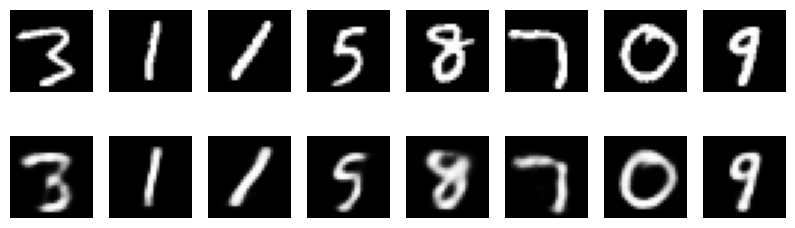

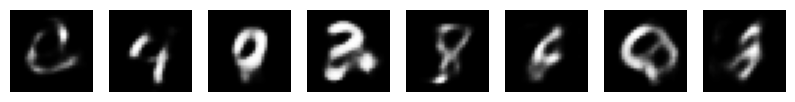

In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 1. Load data
data = datasets.MNIST(
    "./data", train=True, download=True,
    transform=transforms.ToTensor()
)
loader = DataLoader(data, batch_size=128, shuffle=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Define VAE
class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU()
        )
        self.mu = nn.Linear(256, 20)
        self.logvar = nn.Linear(256, 20)

        self.decoder = nn.Sequential(
            nn.Linear(20, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        h = self.encoder(x)
        mu = self.mu(h)
        logvar = self.logvar(h)

        std = torch.exp(0.5 * logvar)
        z = mu + std * torch.randn_like(std)

        return self.decoder(z), mu, logvar

model = VAE().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 3. Train
for epoch in range(5):
    total_loss = 0

    for images, _ in loader:
        images = images.to(device)
        output, mu, logvar = model(images)

        original = images.view(-1, 784)

        recon_loss = nn.functional.binary_cross_entropy(
            output, original, reduction="sum"
        )
        kl_loss = -0.5 * torch.sum(
            1 + logvar - mu.pow(2) - logvar.exp()
        )

        loss = (recon_loss + kl_loss) / images.size(0)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print("Epoch:", epoch + 1,
          "Loss:", total_loss / len(loader))

# 4. Reconstruct images
model.eval()
images, _ = next(iter(loader))
images = images[:8].to(device)

with torch.no_grad():
    output, _, _ = model(images)

plt.figure(figsize=(10, 3))
for i in range(8):
    plt.subplot(2, 8, i + 1)
    plt.imshow(images[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")

    plt.subplot(2, 8, i + 9)
    plt.imshow(output[i].reshape(28, 28).cpu(), cmap="gray")
    plt.axis("off")
plt.show()

# 5. Generate new images
with torch.no_grad():
    z = torch.randn(8, 20).to(device)
    generated = model.decoder(z)

plt.figure(figsize=(10, 2))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(generated[i].reshape(28, 28).cpu(), cmap="gray")
    plt.axis("off")
plt.show()